# Plotting and analyzing data


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import defaultdict
from tqdm import tqdm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# data = readlines("n0.dat")
def getData(filename, startTime, endTime):
    # print(filename)
    with open(filename) as f:
        data = f.readlines()
    time=[]
    val =[]
    for i in data:
        i = i.split(' ')
        t = float(i[0].strip())
        if t<startTime: continue
        if t>endTime: break
        v = int(i[1].strip())
        time.append(t)
        val.append(v)
    f.close()
    # plt.plot(time, val, label="cwnd length alteration of node"+str(random.randint(3, 50)))
    return (time, val)

def getData_pred(filename, startTime, endTime):
    df = pd.read_csv(filename)
    a, b = list(df["Time"]), list(df["Predicted_CWND"])
    time=[]
    val =[]
    for i in range(0, len(a)):
        t = a[i]
        if t<startTime: continue
        if t>endTime: break
        v = round(b[i]/1400)
        time.append(t)
        val.append(v)
    # plt.plot(time, val, label="cwnd length alteration of node"+str(random.randint(3, 50)))
    return (time, val)
def getData_gt(filename, startTime, endTime):
    df = pd.read_csv(filename)
    a, b = list(df["Time"]), list(df["Ground_Truth_CWND"])
    time=[]
    val =[]
    for i in range(0, len(a)):
        t = a[i]
        if t<startTime: continue
        if t>endTime: break
        v = round(b[i]/1400)
        time.append(t)
        val.append(v)
    # plt.plot(time, val, label="cwnd length alteration of node"+str(random.randint(3, 50)))
    return (time, val)

def printData(filename):
    print(filename)
    with open(filename) as f:
        data = f.readlines()
    time=[]
    val =[]
    for i in data:
        i = i.split(' ')
        t = float(i[0].strip())
        # if t<150: continue
        v = int(i[1].strip())
        time.append(t)
        val.append(v)
    f.close()
    print(time)
    print(val)

def plotData(filename, startTime, endTime):
    df = pd.read_csv(filename)
    a, b, c = list(df["Time"]), list(df["Predicted_CWND"]), list(df["Ground_Truth_CWND"])
    time=[]
    val =[]
    valGt =[]
    for i in range(0, len(a)):
        t = a[i]
        if t<startTime: continue
        if t>endTime: break
        v = round(b[i]/1400)
        vgt = round(c[i]/1400)
        time.append(t)
        val.append(v)
        valGt.append(vgt)
    plt.plot(time, val, label="Predicted")
    plt.plot(time, valGt, label="Ground Truth")

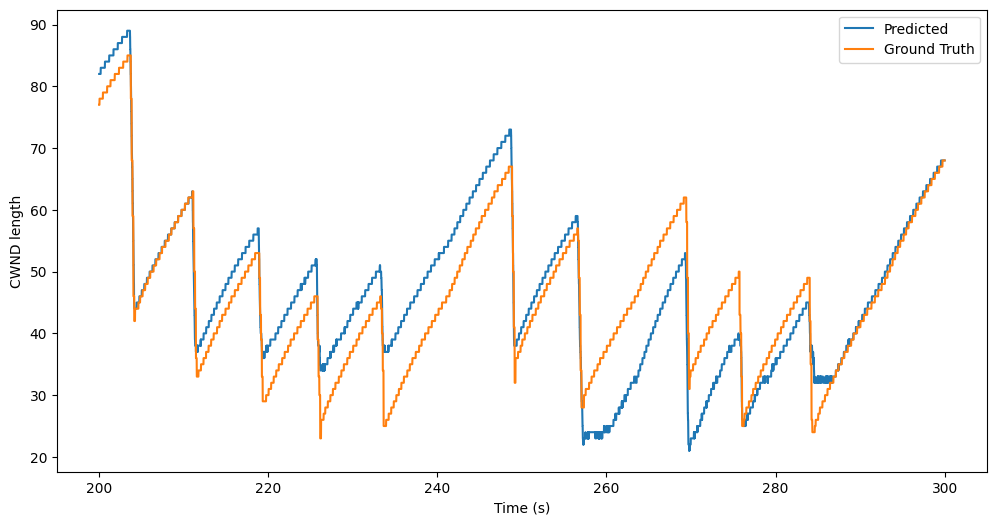

In [ ]:
plt.figure(figsize=(12, 6))
plt.title("")
plotData(f"test_node_predictions_weighted_rf_from_scratch/rf_prediction_data_node_{40}.csv", 200, 300)
plt.xlabel("Time (s)")
plt.ylabel("CWND length")
plt.legend()
plt.show()

#### BETA estimation

In [ ]:
cd /content/drive/MyDrive/CODE-001

/content/drive/MyDrive/CODE-001


In [ ]:
from scipy.signal import find_peaks
# Find indices of the peaks (the top of the sawtooth)
# 'prominence' filters out the small noise oscillations
# 'distance' ensures we don't pick two peaks too close together
# peaks, _ = find_peaks(cwnds, prominence=10, distance=20)

In [ ]:
def getBeta(dir, start_time, end_time):
  start_time = start_time
  till = end_time

  betas = [0 for i in range(62)]
  drops = [0 for i in range(62)]
  for node in range(2, 62):
    t_arr, w_arr = getData_pred(f"{dir}/rf_prediction_data_node_{node}.csv", start_time, till)
    peaks, _ = find_peaks(w_arr, prominence=10, distance=20)
    dips, _ = find_peaks(-1 * np.array(w_arr), prominence=10, distance=20)

    for i in range(len(peaks)):
      j = i
      while j < len(dips) and peaks[i] > dips[j]:
        j += 1
      if j >= len(dips): continue
      betas[node] = (w_arr[peaks[i]] - w_arr[dips[j]])/w_arr[peaks[i]]
      drops[node] += 1
  return sum([betas[i]*drops[i] for i in range(62)]) / sum(drops) if sum(drops) != 0 else -1


def getBeta_fromGt(dir, start_time, end_time):
  start_time = start_time
  till = end_time

  betas = [0 for i in range(62)]
  drops = [0 for i in range(62)]
  for node in range(2, 62):
    t_arr, w_arr = getData_gt(f"{dir}/rf_prediction_data_node_{node}.csv", start_time, till)
    peaks, _ = find_peaks(w_arr, prominence=10, distance=20)
    dips, _ = find_peaks(-1 * np.array(w_arr), prominence=10, distance=20)

    for i in range(len(peaks)):
      j = i
      while j < len(dips) and peaks[i] > dips[j]:
        j += 1
      if j >= len(dips): continue
      betas[node] = (w_arr[peaks[i]] - w_arr[dips[j]])/w_arr[peaks[i]]
      drops[node] += 1
  return sum([betas[i]*drops[i] for i in range(62)]) / sum(drops) if sum(drops) != 0 else -1

In [ ]:
numNode = 44
def getBeta_abc(dir, start_time, end_time):
  from scipy.signal import find_peaks
  start_time = start_time
  till = end_time

  betas = [0 for i in range(numNode)]
  drops = [0 for i in range(numNode)]
  for node in range(2, numNode):
    t_arr, w_arr = getData_pred(f"{dir}/rf_prediction_data_node_{node}.csv", start_time, till)
    peaks, _ = find_peaks(w_arr, prominence=10, distance=20)
    dips, _ = find_peaks(-1 * np.array(w_arr), prominence=10, distance=20)

    for i in range(len(peaks)):
      j = i
      while j < len(dips) and peaks[i] > dips[j]:
        j += 1
      if j >= len(dips): continue
      betas[node] = (w_arr[peaks[i]] - w_arr[dips[j]])/w_arr[peaks[i]]
      drops[node] += 1
  return sum([betas[i]*drops[i] for i in range(numNode)]) / sum(drops) if sum(drops) != 0 else -1


def getBeta_fromGt_abc(dir, start_time, end_time):
  from scipy.signal import find_peaks
  start_time = start_time
  till = end_time

  betas = [0 for i in range(numNode)]
  drops = [0 for i in range(numNode)]
  for node in range(2, numNode):
    t_arr, w_arr = getData_gt(f"{dir}/rf_prediction_data_node_{node}.csv", start_time, till)
    peaks, _ = find_peaks(w_arr, prominence=10, distance=20)
    dips, _ = find_peaks(-1 * np.array(w_arr), prominence=10, distance=20)

    for i in range(len(peaks)):
      j = i
      while j < len(dips) and peaks[i] > dips[j]:
        j += 1
      if j >= len(dips): continue
      betas[node] = (w_arr[peaks[i]] - w_arr[dips[j]])/w_arr[peaks[i]]
      drops[node] += 1
  return sum([betas[i]*drops[i] for i in range(numNode)]) / sum(drops) if sum(drops) != 0 else -1

In [ ]:
getBeta("test_node_predictions_weighted_rf_from_scratch", 100, 180)

100%|██████████| 60/60 [00:11<00:00,  5.37it/s]


0.43018161777710473

In [ ]:
getBeta_fromGt_abc("test_node_predictions_weighted_rf_from_scratch", 100, 130)

0.49127759635997703

### Starting point vs Beta (when threshold hits after 50)

In [ ]:
betas_pred_starting = []
betas_gt_starting = []
x_axis = [i for i in range(10, 400, 10)]
for i in tqdm(x_axis):
  betas_gt_starting.append(getBeta_fromGt("test_node_predictions_weighted_rf_from_scratch", i, i+50))
  betas_pred_starting.append(getBeta("test_node_predictions_weighted_rf_from_scratch", i, i+50))

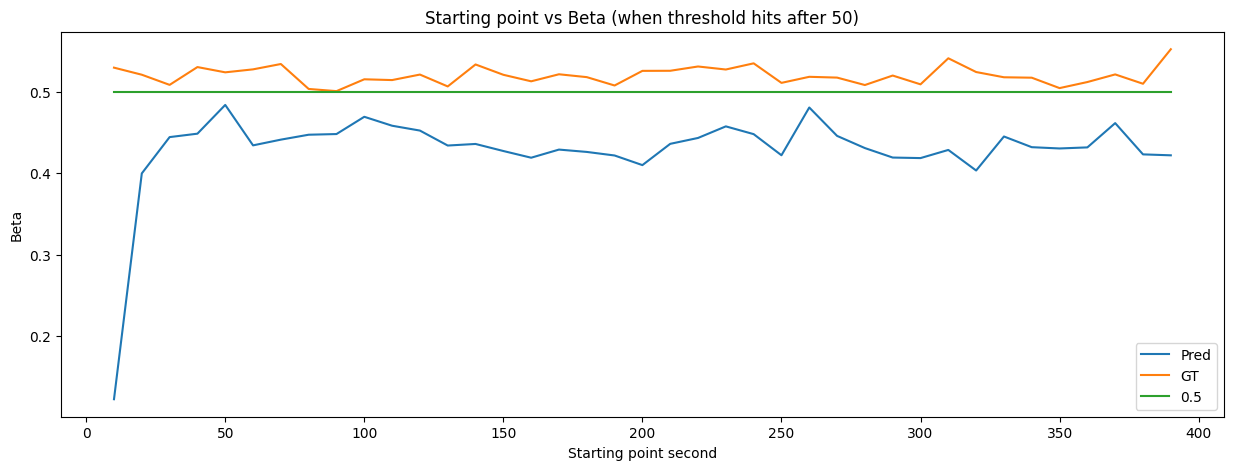

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(x_axis, betas_pred_starting, label = "Pred")
plt.plot(x_axis, betas_gt_starting, label = "GT")
plt.plot(x_axis, [0.5 for i in x_axis], label = "0.5")
plt.title("Starting point vs Beta (when threshold hits after 50)")
plt.xlabel("Starting point second")
plt.ylabel("Beta")
plt.legend()

### Different time gap vs Beta (If starting point is t = 100)

In [ ]:
betas_pred_starting = []
betas_gt_starting = []
x_axis = [i for i in range(10, 200, 10)]
for i in tqdm(x_axis):
  betas_gt_starting.append(getBeta_fromGt("test_node_predictions_weighted_rf_from_scratch", 100, 100 + i))
  betas_pred_starting.append(getBeta("test_node_predictions_weighted_rf_from_scratch", 100, 100 + i))

100%|██████████| 19/19 [06:33<00:00, 20.73s/it]


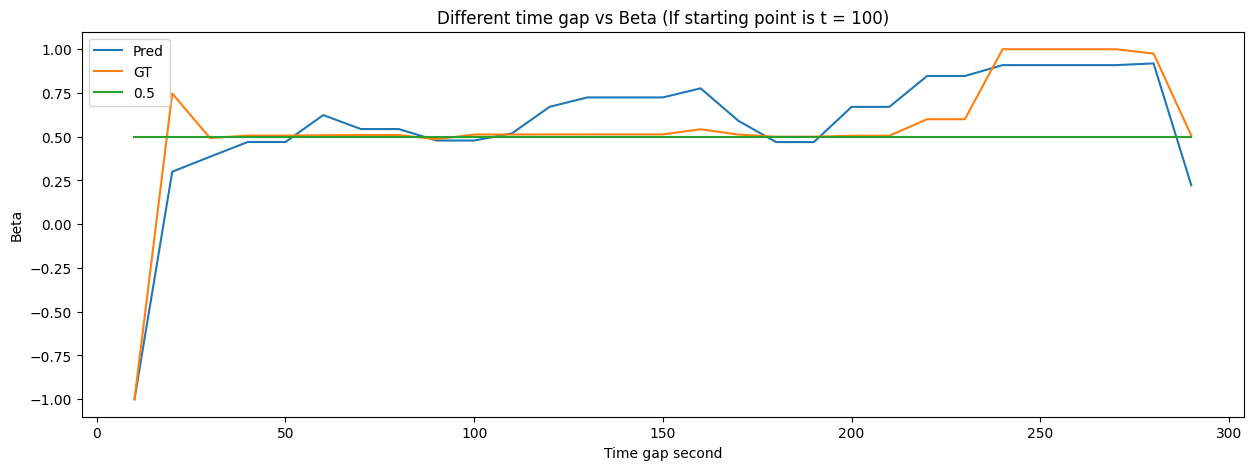

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(x_axis, betas_pred_starting, label = "Pred")
plt.plot(x_axis, betas_gt_starting, label = "GT")
plt.plot(x_axis, [0.5 for i in x_axis], label = "0.5")
plt.title("Different time gap vs Beta (If starting point is t = 100)")
plt.xlabel("Time gap second")
plt.ylabel("Beta")
plt.legend()

In [ ]:
betas_pred_starting = []
betas_gt_starting = []

x_axis = [i for i in range(10, 300, 10)]
for i in tqdm(x_axis, desc=" outer", position=0):
  betas_gt_starting.append(getBeta_fromGt("test_node_predictions_weighted_rf_from_scratch", 50, 50 + i))
  betas_pred_starting.append(getBeta("test_node_predictions_weighted_rf_from_scratch", 50, 50 + i))
  if i == 100:
    print(getBeta_fromGt("test_node_predictions_weighted_rf_from_scratch", 50, 50 + i))
    print(getBeta("test_node_predictions_weighted_rf_from_scratch", 50, 50 + i))



 outer:  31%|███       | 9/29 [02:39<05:59, 17.98s/it]

0.521077041842015


 outer:  34%|███▍      | 10/29 [03:17<07:38, 24.12s/it]

0.46886075325672777


 outer: 100%|██████████| 29/29 [09:53<00:00, 20.47s/it]


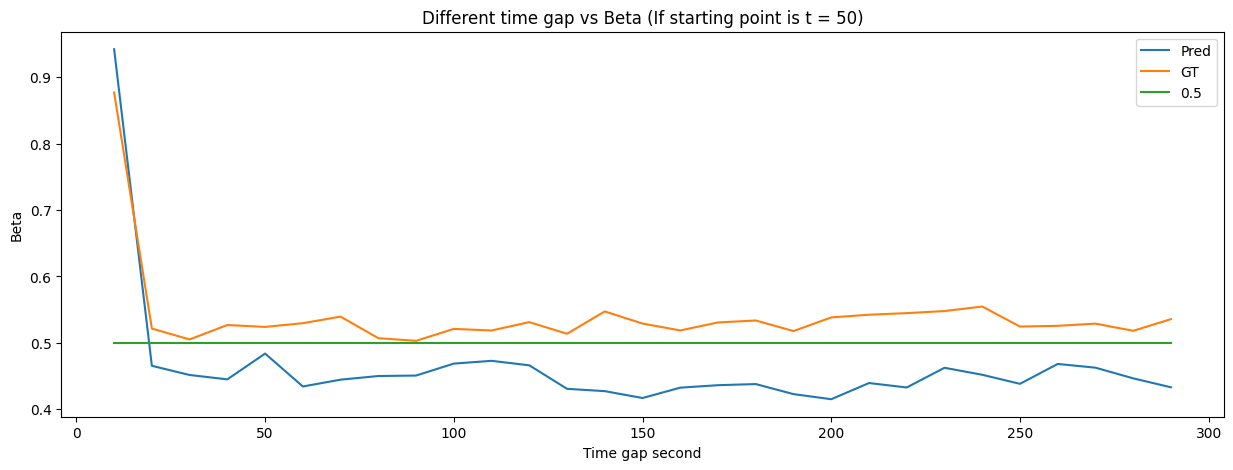

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(x_axis, betas_pred_starting, label = "Pred")
plt.plot(x_axis, betas_gt_starting, label = "GT")
plt.plot(x_axis, [0.5 for i in x_axis], label = "0.5")
plt.title("Different time gap vs Beta (If starting point is t = 50)")
plt.xlabel("Time gap second")
plt.ylabel("Beta")
plt.legend()

In [ ]:
print(getBeta_fromGt_abc("test_node_predictions_weighted_rf_from_scratch", 50, 50 + 100))
print(getBeta_abc("test_node_predictions_weighted_rf_from_scratch", 50, 50 + 100))

0.521548163580736
0.4550879952072131


## Parking Lot

In [ ]:
def getBetaPL(dir, start_time, end_time, numNode=63):
  start_time = start_time
  till = end_time

  betas = [0 for i in range(numNode)]
  drops = [0 for i in range(numNode)]
  for node in range(3, numNode):
    t_arr, w_arr = getData_pred(f"{dir}/rf_prediction_data_node_{node}.csv", start_time, till)
    peaks, _ = find_peaks(w_arr, prominence=10, distance=20)
    dips, _ = find_peaks(-1 * np.array(w_arr), prominence=10, distance=20)

    for i in range(len(peaks)):
      j = i
      while j < len(dips) and peaks[i] > dips[j]:
        j += 1
      if j >= len(dips): continue
      betas[node] = (w_arr[peaks[i]] - w_arr[dips[j]])/w_arr[peaks[i]]
      drops[node] += 1
  return sum([betas[i]*drops[i] for i in range(len(betas))]) / sum(drops) if sum(drops) != 0 else -1


def getBeta_fromGtPL(dir, start_time, end_time, numNode=63):
  start_time = start_time
  till = end_time

  betas = [0 for i in range(numNode)]
  drops = [0 for i in range(numNode)]
  for node in range(3, numNode):
    t_arr, w_arr = getData_gt(f"{dir}/rf_prediction_data_node_{node}.csv", start_time, till)
    peaks, _ = find_peaks(w_arr, prominence=10, distance=20)
    dips, _ = find_peaks(-1 * np.array(w_arr), prominence=10, distance=20)

    for i in range(len(peaks)):
      j = i
      while j < len(dips) and peaks[i] > dips[j]:
        j += 1
      if j >= len(dips): continue
      betas[node] = (w_arr[peaks[i]] - w_arr[dips[j]])/w_arr[peaks[i]]
      drops[node] += 1
  return sum([betas[i]*drops[i] for i in range(len(betas))]) / sum(drops) if sum(drops) != 0 else -1

#### Router 1

In [ ]:
betas_pred_starting = []
betas_gt_starting = []

x_axis = [i for i in range(10, 300, 10)]
for i in tqdm(x_axis, desc="outer", position=0):
  betas_gt_starting.append(getBeta_fromGtPL("parkingLot3/test_node_predictions_weighted_rf_from_scratch_0", 50, 50 + i))
  betas_pred_starting.append(getBetaPL("parkingLot3/test_node_predictions_weighted_rf_from_scratch_0", 50, 50 + i))
  if i == 100:
    print(getBeta_fromGtPL("parkingLot3/test_node_predictions_weighted_rf_from_scratch_0", 50, 50 + i))
    print(getBetaPL("parkingLot3/test_node_predictions_weighted_rf_from_scratch_0", 50, 50 + i))

outer:  31%|███       | 9/29 [03:10<05:59, 17.98s/it]

0.5500600844214952


outer:  34%|███▍      | 10/29 [03:45<07:24, 23.38s/it]

0.6305305344291302


outer: 100%|██████████| 29/29 [09:52<00:00, 20.42s/it]


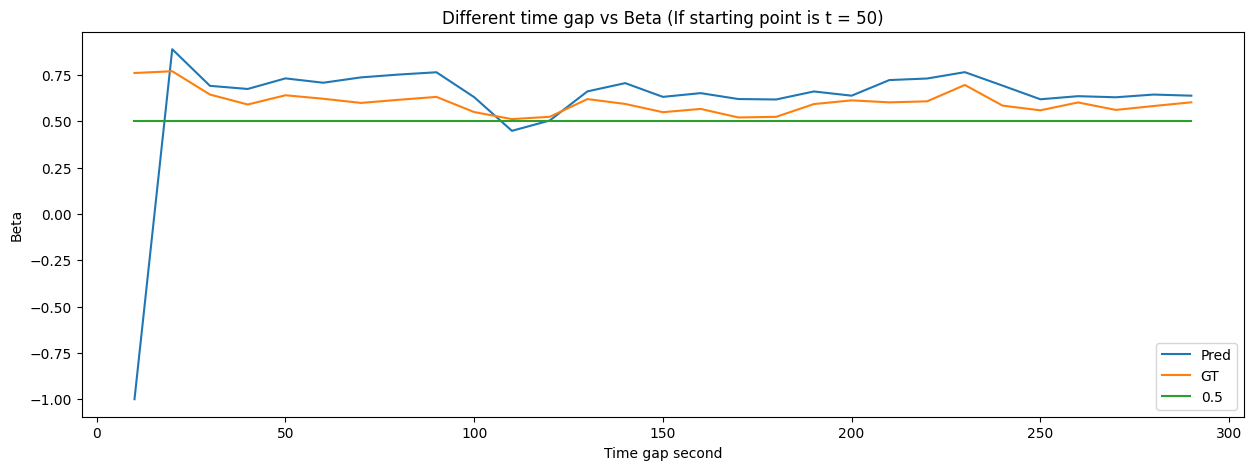

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(x_axis, betas_pred_starting, label = "Pred")
plt.plot(x_axis, betas_gt_starting, label = "GT")
plt.plot(x_axis, [0.5 for i in x_axis], label = "0.5")
plt.title("Different time gap vs Beta (If starting point is t = 50)")
plt.xlabel("Time gap second")
plt.ylabel("Beta")
plt.legend()

#### Router 2

In [ ]:
def getBetaPL(dir, start_time, end_time, numNode=63+30):
  start_time = start_time
  till = end_time

  betas = [0 for i in range(numNode)]
  drops = [0 for i in range(numNode)]
  for node in range(3+30, numNode):
    t_arr, w_arr = getData_pred(f"{dir}/rf_prediction_data_node_{node}.csv", start_time, till)
    peaks, _ = find_peaks(w_arr, prominence=10, distance=20)
    dips, _ = find_peaks(-1 * np.array(w_arr), prominence=10, distance=20)

    for i in range(len(peaks)):
      j = i
      while j < len(dips) and peaks[i] > dips[j]:
        j += 1
      if j >= len(dips): continue
      betas[node] = (w_arr[peaks[i]] - w_arr[dips[j]])/w_arr[peaks[i]]
      drops[node] += 1
  return sum([betas[i]*drops[i] for i in range(len(betas))]) / sum(drops) if sum(drops) != 0 else -1


def getBeta_fromGtPL(dir, start_time, end_time, numNode=63+30):
  start_time = start_time
  till = end_time

  betas = [0 for i in range(numNode)]
  drops = [0 for i in range(numNode)]
  for node in range(3+30, numNode):
    t_arr, w_arr = getData_gt(f"{dir}/rf_prediction_data_node_{node}.csv", start_time, till)
    peaks, _ = find_peaks(w_arr, prominence=10, distance=20)
    dips, _ = find_peaks(-1 * np.array(w_arr), prominence=10, distance=20)

    for i in range(len(peaks)):
      j = i
      while j < len(dips) and peaks[i] > dips[j]:
        j += 1
      if j >= len(dips): continue
      betas[node] = (w_arr[peaks[i]] - w_arr[dips[j]])/w_arr[peaks[i]]
      drops[node] += 1
  return sum([betas[i]*drops[i] for i in range(len(betas))]) / sum(drops) if sum(drops) != 0 else -1

In [ ]:
betas_pred_starting = []
betas_gt_starting = []

x_axis = [i for i in range(10, 300, 10)]
for i in tqdm(x_axis, desc="outer", position=0):
  betas_gt_starting.append(getBeta_fromGtPL("parkingLot3/test_node_predictions_weighted_rf_from_scratch_1", 50, 50 + i))
  betas_pred_starting.append(getBetaPL("parkingLot3/test_node_predictions_weighted_rf_from_scratch_1", 50, 50 + i))
  if i == 100:
    print(getBeta_fromGtPL("parkingLot3/test_node_predictions_weighted_rf_from_scratch_1", 50, 50 + i))
    print(getBetaPL("parkingLot3/test_node_predictions_weighted_rf_from_scratch_1", 50, 50 + i))

outer:  31%|███       | 9/29 [02:56<06:02, 18.14s/it]

0.6876410689640772


outer:  34%|███▍      | 10/29 [03:35<07:45, 24.53s/it]

0.7506929276282786


outer: 100%|██████████| 29/29 [10:02<00:00, 20.78s/it]


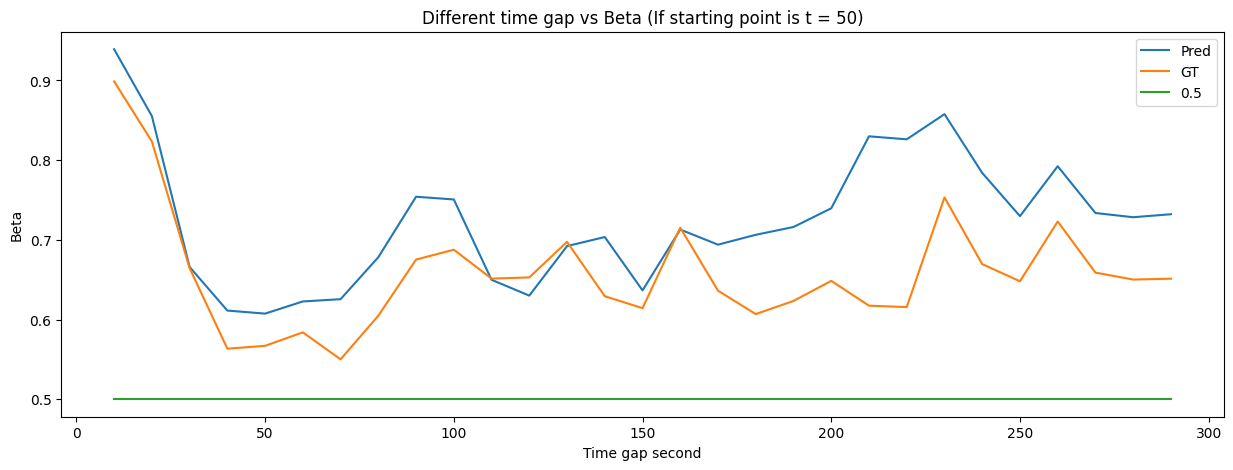

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(x_axis, betas_pred_starting, label = "Pred")
plt.plot(x_axis, betas_gt_starting, label = "GT")
plt.plot(x_axis, [0.5 for i in x_axis], label = "0.5")
plt.title("Different time gap vs Beta (If starting point is t = 50)")
plt.xlabel("Time gap second")
plt.ylabel("Beta")
plt.legend()